# 09 (PH) - Model comparison: one look at the test period

**Who worked on this notebook**

| Who | What |
| --- | --- |
| Peter Henskens | Keeps the split of 03 §6.3 (the test period, January - August 2026, is scored once, here); decided after 08 to stop tuning and let this notebook decide; confirmed the rule of choice of part 1 before the run; ran the notebook on the test period on 8 October and again on 10 October with 10's candidates; reviews the choice |
| Claude Code (AI assistant) | Drafted the candidate registry, the test scoring through the saved pipelines (`model_predictions()` in `modelling.py`), the tables, the cuts, the charts, the choice file, the checks and the dry run of 8 October (appendix). Logged in `genai-log.md` |

**Goal.** 05 - 08 chose, trained and tuned on 2021 - 2025 and never touched 2026. This notebook scores every
candidate **once on the test period**: the rules of 05, the ridge floor of 05, the models of 07 (trained once) and
08 (tuned) and, when its run folder is there, the model 10 trains on SageMaker. Same rows, same four metrics (MAE,
RMSE, WAPE, bias), same `score_table()` as 05 - 08, per horizon. It then names the **final model per horizon** by a
rule fixed before the numbers are seen, reads where that model is good and where it fails, and writes the choice
to a file the deployment reads. Nothing is trained or tuned here, and nothing is tuned after it: a test score that
steers a change is a validation score.

**Products**

| Product | What it is |
| --- | --- |
| the candidate table of part 1 | every candidate with its notebook, family, trees, settings, validation MAE and size; present or missing |
| the test tables of parts 3 and 4 | every method on all scorable test rows per horizon, with its validation MAE next to it |
| the cuts of parts 3 - 5 | per month of 2026, holidays, rain, station size, days left in the month, the city total per day, one station |
| `models/citibike/09_choice.json` | the final model per horizon: run folder, family, hyperparameters, inputs, test and validation metrics; what the API and the retraining pipeline read |

**How it is built**
0. Setup.
1. The protocol: one look, the candidates, the rule of choice.
2. The test rows and every candidate's predictions, with checks.
3. Horizon day: the test table, validation next to test, per month, the cuts.
4. Horizon rest of month: the test table, per days left, per month.
5. The city total per day, and one station.
6. The choice, written to disk.
7. Reading and conclusions.
Appendix: the dry run of 8 October, the expected runtime, the failures to expect.

**Status: run on the test period on 8 October 2026 and again on 10 October with the candidates of 10 (team lead).**
The dry run of the appendix ran every cell on a station sample first; the outputs above are the second run and the
reading in part 7 is written from them.

## 0. Setup

Kernel "DataSpell", as 07 and 08; no database connection: the feature table comes from the Parquet cache of 05 §5,
the test inputs from `data/citibike/model_inputs/<horizon>/test.parquet` (written by 07 §2 and read by no
notebook until now), the models from their run folders. The predictions go through `modelling.model_predictions()`,
which applies a saved pipeline exactly as `train.py` does (output x scale, never below 0). `lightgbm` is imported
so that a LightGBM pipeline can be unpickled, and for its version.

In [3]:
import gc
import json
import sys
import time
from datetime import date

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

sys.path.insert(0, "..")         # citibike/ -> connection.py and modelling.py
from connection import fmt, notebook_style
from modelling import (load_features, scorable, score_table, rule_predictions, ridge_predictions, run_predictions,
                       model_predictions, TARGETS, MODEL_INPUTS_DIR, MODELS_DIR)

notebook_style()
print(f"python {sys.version.split()[0]}, scikit-learn {sklearn.__version__}, lightgbm {lightgbm.__version__}, pandas {pd.__version__}")

HORIZONS = ["day", "rest_of_month"]
CANDIDATES = {   # label -> run folder under models/citibike/ (model.joblib + metrics.json); a missing one is reported and skipped
    "day": {"lightgbm (07)": "07_day_lightgbm",
            "lightgbm (08, tuned)": "08_day_lightgbm",
            "lightgbm (10, SageMaker)": "10_day_lightgbm"},
    "rest_of_month": {"extra trees (07)": "07_rest_of_month_extra_trees",
                      "extra trees (08, tuned)": "08_rest_of_month_extra_trees",
                      "extra trees (10, SageMaker)": "10_rest_of_month_extra_trees"},
}
TIE_PERCENT = 1.0                                   # part 1: within this of the lowest test MAE, the smaller model wins
CHOICE_FILE = MODELS_DIR / "09_choice.json"
for horizon in HORIZONS:
    assert (MODEL_INPUTS_DIR / horizon / "test.parquet").exists(), f"run 07 §2 first: no test inputs for {horizon}"

python 3.13.7, scikit-learn 1.9.1, lightgbm 4.7.0, pandas 2.3.3


## 1. The protocol: one look, the candidates, the rule of choice

**One look.** The split of 03 §6.3 kept 2026 out of every choice so far: the families were chosen on 2025 (06), the
hyperparameters on 2025 (08); the rules were *reported* on 2026 in 05 because they fit nothing. This notebook
spends the test period. Whatever it shows, the models are not changed afterwards: a second round of tuning
"because the test said so" would turn the test period into a second validation year and the score into a promise
the API cannot keep. When 10 adds its candidate, it is scored here on the same rows with the same rule, once.

**The candidates** per horizon, all on the same scorable test rows (28 days of history and an observed target):

| Candidate | Where it comes from | Trained on |
| --- | --- | --- |
| three rules | 05 §6: for the day, yesterday, the same weekday last week, the 4-week mean; for the rest of the month, the month-to-date pace, the weekly pace, last year scaled | nothing |
| ridge (05) | 05 §7, the saved pipeline; the floor every model had to beat | 2021 - 2024 |
| 07 model | the family 06 chose, trained once with sensible settings | 2021 - 2024 |
| 08 model | the same family, the winner of 08's search, refitted | 2021 - 2024 |
| 10 model | the same family and script, the winner of the SageMaker search, when `10_<horizon>_<family>/` holds `model.joblib` and `metrics.json` (10 unpacks its `model.tar.gz` and `output.tar.gz` there) | 2021 - 2024 |

06's sample-fitted models are not candidates: they were fitted on 10 % of the stations as a reference for 07, in
another environment (PyCaret); their argument, the leaderboard, is in 06. Every model predicts 2026 from a fit on
2021 - 2024 with 2025 unseen: the gap between validation and test is partly that year, and the same for every
candidate. Retraining the final model on 2021 - 2025 is the deployment's job (the retraining pipeline), not this
notebook's. The year-earlier rule enters as 05 left it (05 §9 suggested capping its growth factor before 09; it was
not capped, so that this table and the tables of 05 - 08 show the same rule).

**Decision: the rule of choice, fixed before the test table is seen.** Per horizon, the candidate with the lowest
test **MAE** wins (05 - 08's metric: departures per station-day, the number an operator feels). When two candidates
are within `TIE_PERCENT` (1 %) of each other, the **smaller model file** wins: the API loads it on every start and
the retraining pipeline rebuilds it on every push, and a difference of 1 % on 537.000 rows is real but not worth a
model twice the size. Alternatives not taken: the WAPE (the same errors weighted by volume, shown next to the MAE
but not ranked on), the RMSE (dominated by the storm days of the busy stations, which no candidate predicts well), a
composite (a number nobody can explain). The rules and the ridge are in the table as the bar, not as candidates: a
model that lost to a rule would be the finding of this notebook, not a choice.

**The candidate table**: what is on disk, read from each run folder's `metrics.json`.

In [4]:
def run_summary(label: str, folder: str) -> dict:
    """One row per candidate: what its run folder holds, or that it is missing."""
    run_dir = MODELS_DIR / folder
    row = {"candidate": label, "run folder": folder, "present": False, "family": None, "trees": None, "settings": None,
           "inputs": None, "training rows": None, "validation MAE": None, "model MB": None}
    if (run_dir / "metrics.json").exists() and (run_dir / "model.joblib").exists():
        result = json.loads((run_dir / "metrics.json").read_text(encoding="utf-8"))
        params = result["hyperparameters"]
        row.update({"present": True, "family": result["family"], "trees": params["n_estimators"],
                    "settings": ", ".join(f"{k}={v}" for k, v in params.items()
                                          if k not in ("n_estimators", "station_key", "sample_stations", "seed", "n_jobs")),
                    "inputs": len(result["inputs"]), "training rows": result["rows"]["train"],
                    "validation MAE": round(result["validation"]["MAE"], 2),
                    "model MB": round((run_dir / "model.joblib").stat().st_size / 1e6, 1)})
    return row


registry = pd.concat({horizon: pd.DataFrame([run_summary(label, folder) for label, folder in CANDIDATES[horizon].items()]).set_index("candidate")
                      for horizon in HORIZONS}, names=["horizon", "candidate"])
for (horizon, label), row in registry[~registry.present].iterrows():
    print(f"{horizon}: {label} is not on disk ({row['run folder']}): scored once 10 has run, skipped until then")
assert registry.present.groupby(level="horizon").any().all(), "no candidate on disk for a horizon: run 07 first"
registry.drop(columns="present").astype({"trees": "Int64", "inputs": "Int64", "training rows": "Int64"})

run folder  \
horizon       candidate                                                   
day           lightgbm (07)                             07_day_lightgbm   
              lightgbm (08, tuned)                      08_day_lightgbm   
              lightgbm (10, SageMaker)                  10_day_lightgbm   
rest_of_month extra trees (07)             07_rest_of_month_extra_trees   
              extra trees (08, tuned)      08_rest_of_month_extra_trees   
              extra trees (10, SageMaker)  10_rest_of_month_extra_trees   

                                                family  trees  \
horizon       candidate                                         
day           lightgbm (07)                   lightgbm   1000   
              lightgbm (08, tuned)            lightgbm    500   
              lightgbm (10, SageMaker)        lightgbm   1000   
rest_of_month extra trees (07)             extra_trees    200   
              extra trees (08, tuned)      extra_trees    200   
              extra trees (10, SageMaker)  extra_trees    200   

                                                                                    settings  \
horizon       candidate                                                                        
day           lightgbm (07)                objective=regression, learning_rate=0.05, num_...   
              lightgbm (08, tuned)         objective=regression_l1, learning_rate=0.049, ...   
              lightgbm (10, SageMaker)     objective=regression_l1, learning_rate=0.02168...   
rest_of_month extra trees (07)                        min_samples_leaf=100, max_features=1.0   
              extra trees (08, tuned)                  min_samples_leaf=50, max_features=1.0   
              extra trees (10, SageMaker)              min_samples_leaf=25, max_features=1.0   

                                           inputs  training rows  \
horizon       candidate                                            
day           lightgbm (07)                    23        2480425   
              lightgbm (08, tuned)             23        2480425   
              lightgbm (10, SageMaker)         23        2480425   
rest_of_month extra trees (07)                 22        2476569   
              extra trees (08, tuned)          22        2476569   
              extra trees (10, SageMaker)      22        2476569   

                                           validation MAE  model MB  
horizon       candidate                                              
day           lightgbm (07)                         10.02       5.8  
              lightgbm (08, tuned)                   9.63      12.2  
              lightgbm (10, SageMaker)               9.53      46.4  
rest_of_month extra trees (07)                     109.90     498.7  
              extra trees (08, tuned)              108.47    1005.6  
              extra trees (10, SageMaker)          107.47    2038.8

## 2. The test rows and every candidate's predictions

The scorable test rows of the feature table per horizon (05 §5: 537.818 for the day, 536.450 for the rest of the
month) and the test inputs 07 §2 wrote for them, which must be the same station-days in the same order. Then the
predictions of every method as one Series per method on the rows' index, the form `score_table()` takes: the
rules from the table's own columns, the ridge from its saved pipeline through `design()`, each model from its
`model.joblib` through `model_predictions()`, loaded one at a time (the extra trees of 08 are 1 GB). One check per
model before it is trusted on 2026: on 2.000 validation rows its pipeline must reproduce the
`predictions_valid.parquet` its notebook scored, so that the model on disk is the model whose validation MAE the
tables quote; those rows ride along with the test rows in one call, so each pipeline is loaded once.

In [5]:
df = load_features()
test = {horizon: df[(df.split == "test") & scorable(df, horizon)] for horizon in HORIZONS}
inputs = {horizon: pd.read_parquet(MODEL_INPUTS_DIR / horizon / "test.parquet") for horizon in HORIZONS}


def keys_of(d: pd.DataFrame) -> pd.MultiIndex:
    return pd.MultiIndex.from_arrays([d.station_key.astype(str), d.day.astype("datetime64[ns]")])


for horizon in HORIZONS:
    rows, x = test[horizon], inputs[horizon]
    assert keys_of(rows).equals(keys_of(x)), f"{horizon}: the test inputs are not the scorable test rows of the cache, in order: run 07 §2 again"
    print(f"{horizon}: {fmt(len(rows))} scorable test rows, {fmt(rows.station_key.nunique())} stations, "
          f"{rows.day.min():%Y-%m-%d} to {rows.day.max():%Y-%m-%d}; the test inputs match")

probe, probe_inputs = {}, {}          # 2.000 validation rows per horizon, with their inputs: the check that a pipeline is the one its run scored
for horizon in HORIZONS:
    probe[horizon] = df[(df.split == "valid") & scorable(df, horizon)].sample(2000, random_state=0)
    valid_inputs = pd.read_parquet(MODEL_INPUTS_DIR / horizon / "valid.parquet")
    probe_inputs[horizon] = valid_inputs[keys_of(valid_inputs).isin(keys_of(probe[horizon]))]
    assert len(probe_inputs[horizon]) == len(probe[horizon]), f"{horizon}: the validation inputs are not the validation rows of the cache"
    del valid_inputs

predictions = {}
for horizon in HORIZONS:
    rows = test[horizon]
    predictions[horizon] = rule_predictions(rows, horizon)
    ridge = ridge_predictions(horizon, rows)
    if ridge is not None:
        predictions[horizon]["ridge (05)"] = ridge
    for label, folder in CANDIDATES[horizon].items():
        if not registry.loc[(horizon, label), "present"]:
            continue
        t0 = time.time()
        both = model_predictions(MODELS_DIR / folder, pd.concat([probe[horizon], rows]), pd.concat([probe_inputs[horizon], inputs[horizon]]))
        gap = (both.loc[probe[horizon].index] - run_predictions(MODELS_DIR / folder, probe[horizon])).abs().max()
        assert gap < 1e-6, f"{label}: the pipeline on disk differs from its saved validation predictions by up to {gap:.4f}"
        predictions[horizon][label] = both.loc[rows.index]
        del both
        gc.collect()
        print(f"{horizon}: {label} reproduces its saved validation predictions on {fmt(len(probe[horizon]))} rows; "
              f"{fmt(len(rows))} test predictions in {time.time() - t0:.0f} s")

3.872.821 rows from data\citibike\station_day_features.parquet
day: 537.818 scorable test rows, 2.328 stations, 2026-01-01 to 2026-08-31; the test inputs match
rest_of_month: 536.450 scorable test rows, 2.325 stations, 2026-01-01 to 2026-08-31; the test inputs match
day: lightgbm (07) reproduces its saved validation predictions on 2.000 rows; 537.818 test predictions in 7 s
day: lightgbm (08, tuned) reproduces its saved validation predictions on 2.000 rows; 537.818 test predictions in 8 s
day: lightgbm (10, SageMaker) reproduces its saved validation predictions on 2.000 rows; 537.818 test predictions in 19 s
rest_of_month: extra trees (07) reproduces its saved validation predictions on 2.000 rows; 536.450 test predictions in 6 s
rest_of_month: extra trees (08, tuned) reproduces its saved validation predictions on 2.000 rows; 536.450 test predictions in 8 s
rest_of_month: extra trees (10, SageMaker) reproduces its saved validation predictions on 2.000 rows; 536.450 test predictions in 1

## 3. Horizon day

### 3.1 The test table, with the validation MAE next to it

Every method on all scorable test rows of January - August 2026, the four metrics of 05, sorted on the MAE; the
validation MAE of 2025 in front (the models' from their `metrics.json`, the rules' and the ridge's computed here on
the validation rows) and the shift from validation to test in percent. Read the shift with care: the test period is
eight months without an autumn, on stations a year older, with 2025 unseen by every model. A shift that is the same
for every method is the period; a shift that differs between methods is the finding.

In [6]:
def with_validation(horizon: str, table: pd.DataFrame) -> pd.DataFrame:
    """The test table with the validation MAE of every method in front: the models' from their run, the rest computed."""
    valid = df[(df.split == "valid") & scorable(df, horizon)]
    on_valid = rule_predictions(valid, horizon)
    ridge = ridge_predictions(horizon, valid)
    if ridge is not None:
        on_valid["ridge (05)"] = ridge
    validation = score_table(valid, on_valid, TARGETS[horizon])["MAE"].to_dict()
    for label, folder in CANDIDATES[horizon].items():
        if registry.loc[(horizon, label), "present"]:
            validation[label] = json.loads((MODELS_DIR / folder / "metrics.json").read_text(encoding="utf-8"))["validation"]["MAE"]
    out = table.copy()
    out.insert(0, "validation MAE", pd.Series(validation))
    out.insert(2, "shift %", (out.MAE / out["validation MAE"] - 1) * 100)
    return out.sort_values("MAE")


table_day = with_validation("day", score_table(test["day"], predictions["day"], "y_day"))
print(f"Test 2026, horizon day, {fmt(len(test['day']))} station-days")
table_day.round(2)

Test 2026, horizon day, 537.818 station-days


,validation MAE,MAE,shift %,RMSE,WAPE_%,bias,n
method,,,,,,,
"lightgbm (10, SageMaker)","9,53","9,75","2,23","19,24","17,48","-1,74",537.818
"lightgbm (08, tuned)","9,63","9,80","1,75","19,40","17,58","-1,74",537.818
lightgbm (07),"10,02","10,08","0,59","19,24","18,07","1,00",537.818
ridge (05),"11,92","12,60","5,72","24,10","22,59","-0,97",537.818
naive (yesterday),"14,87","15,43","3,77","30,98","27,66","-0,20",537.818
"mean of the same weekday, 4 weeks","14,57","15,57","6,83","30,72","27,92","-3,63",537.818
seasonal naive (same weekday last week),"16,08","17,77","10,50","35,81","31,87","-1,71",537.818


### 3.2 Per month of 2026, and the cuts of 05 and 07

The MAE and WAPE per month for the two best rules, the ridge and the models: the test period runs from winter into
summer and the demand triples between them, so a method's MAE grows with the volume while its WAPE should not. Then
the cuts of 05 §8 and 07 §5 on the test rows: holidays and the week after, wet days, station-size quartiles.

In [7]:
shown_day = [m for m in ["seasonal naive (same weekday last week)", "mean of the same weekday, 4 weeks", "ridge (05)", *CANDIDATES["day"]]
             if m in predictions["day"]]
shown = {m: predictions["day"][m] for m in shown_day}
by_month = test["day"].assign(month=test["day"].day.dt.strftime("%Y-%m"))
monthly = score_table(by_month, shown, "y_day", by="month")
print("Test 2026, horizon day: MAE per month (left) and WAPE % (right)")
display(pd.concat({"MAE": monthly.MAE.unstack("method")[shown_day].round(2),
                   "WAPE_%": monthly["WAPE_%"].unstack("method")[shown_day].round(1)}, axis=1))

cuts = test["day"].assign(**{
    "day group": np.select([test["day"].holiday, test["day"].holiday_lag_7], ["holiday", "a week after a holiday"], "other day"),
    "rain": np.where(test["day"].prcp_mm > 2, "wet (> 2 mm)", "dry"),
    "station size": pd.qcut(test["day"].dep_mean_4_weeks, 4, labels=["Q1 quiet", "Q2", "Q3", "Q4 busy"], duplicates="drop"),
})
for by in ["day group", "rain", "station size"]:
    print(f"Test 2026, horizon day, by {by}")
    display(score_table(cuts, shown, "y_day", by=by).round(2))

Test 2026, horizon day: MAE per month (left) and WAPE % (right)


MAE  \
method  seasonal naive (same weekday last week)   
month                                             
2026-01                                   15.53   
2026-02                                   10.09   
2026-03                                   18.80   
2026-04                                   19.69   
2026-05                                   22.24   
2026-06                                   18.15   
2026-07                                   21.80   
2026-08                                   15.13   

                                                                    \
method  mean of the same weekday, 4 weeks ridge (05) lightgbm (07)   
month                                                                
2026-01                             14.59       8.91          6.34   
2026-02                              9.64       6.55          5.40   
2026-03                             17.80      13.23         10.06   
2026-04                             16.22      14.11         10.10   
2026-05                             16.85      14.12         10.67   
2026-06                             16.78      13.78         13.08   
2026-07                             17.83      15.40         12.36   
2026-08                             14.26      14.00         12.08   

                                                       \
method  lightgbm (08, tuned) lightgbm (10, SageMaker)   
month                                                   
2026-01                 6.27                     6.41   
2026-02                 5.27                     5.23   
2026-03                10.33                    10.34   
2026-04                10.00                     9.81   
2026-05                10.19                    10.15   
2026-06                12.43                    12.37   
2026-07                11.87                    11.67   
2026-08                11.56                    11.48   

                                         WAPE_%  \
method  seasonal naive (same weekday last week)   
month                                             
2026-01                                    58.2   
2026-02                                    51.0   
2026-03                                    43.7   
2026-04                                    33.9   
2026-05                                    32.6   
2026-06                                    22.6   
2026-07                                    30.6   
2026-08                                    20.4   

                                                                    \
method  mean of the same weekday, 4 weeks ridge (05) lightgbm (07)   
month                                                                
2026-01                              54.7       33.4          23.8   
2026-02                              48.7       33.1          27.3   
2026-03                              41.3       30.7          23.3   
2026-04                              27.9       24.3          17.4   
2026-05                              24.7       20.7          15.6   
2026-06                              20.8       17.1          16.3   
2026-07                              25.0       21.6          17.3   
2026-08                              19.2       18.8          16.3   

                                                       
method  lightgbm (08, tuned) lightgbm (10, SageMaker)  
month                                                  
2026-01                 23.5                     24.0  
2026-02                 26.6                     26.4  
2026-03                 24.0                     24.0  
2026-04                 17.2                     16.9  
2026-05                 14.9                     14.9  
2026-06                 15.4                     15.4  
2026-07                 16.6                     16.4  
2026-08                 15.6                     15.5

Test 2026, horizon day, by day group


,,MAE,RMSE,WAPE_%,bias,n
day group,method,,,,,
a week after a holiday,seasonal naive (same weekday last week),"22,84","43,64","50,18","-7,91",19.859
holiday,seasonal naive (same weekday last week),"17,33","37,31","45,99","6,44",19.822
other day,seasonal naive (same weekday last week),"17,59","35,40","30,92","-1,79",498.137
a week after a holiday,"mean of the same weekday, 4 weeks","13,99","27,47","30,73","-1,14",19.859
holiday,"mean of the same weekday, 4 weeks","17,91","36,79","47,51","10,15",19.822
other day,"mean of the same weekday, 4 weeks","15,54","30,58","27,31","-4,28",498.137
a week after a holiday,ridge (05),"11,54","22,93","25,36","-3,01",19.859
holiday,ridge (05),"13,20","25,32","35,02","1,67",19.822
other day,ridge (05),"12,62","24,10","22,18","-0,99",498.137


Test 2026, horizon day, by rain


,,MAE,RMSE,WAPE_%,bias,n
rain,method,,,,,
dry,seasonal naive (same weekday last week),"17,10","34,04","29,68","-5,50",408.992
wet (> 2 mm),seasonal naive (same weekday last week),"19,90","40,93","39,94","10,31",128.826
dry,"mean of the same weekday, 4 weeks","15,23","29,76","26,43","-6,75",408.992
wet (> 2 mm),"mean of the same weekday, 4 weeks","16,62","33,59","33,37","6,28",128.826
dry,ridge (05),"12,20","23,05","21,16","-3,06",408.992
wet (> 2 mm),ridge (05),"13,87","27,18","27,84","5,67",128.826
dry,lightgbm (07),"9,87","18,96","17,13","0,37",408.992
wet (> 2 mm),lightgbm (07),"10,72","20,10","21,51","3,01",128.826
dry,"lightgbm (08, tuned)","9,64","19,21","16,73","-2,48",408.992


Test 2026, horizon day, by station size


,,MAE,RMSE,WAPE_%,bias,n
station size,method,,,,,
Q1 quiet,seasonal naive (same weekday last week),"3,27","7,51","63,07","-1,08",136.865
Q2,seasonal naive (same weekday last week),"6,88","10,11","45,07","-1,18",132.892
Q3,seasonal naive (same weekday last week),"16,77","25,40","38,11","-3,02",133.720
Q4 busy,seasonal naive (same weekday last week),"44,32","65,83","27,87","-1,58",134.341
Q1 quiet,"mean of the same weekday, 4 weeks","2,97","7,34","57,25","-1,32",136.865
Q2,"mean of the same weekday, 4 weeks","6,09","9,48","39,90","-1,86",132.892
Q3,"mean of the same weekday, 4 weeks","15,02","23,75","34,14","-4,80",133.720
Q4 busy,"mean of the same weekday, 4 weeks","38,31","55,44","24,09","-6,56",134.341
Q1 quiet,ridge (05),"3,92","6,44","75,63","1,13",136.865


## 4. Horizon rest of month

### 4.1 The test table, with the validation MAE next to it

The same table for the rest of the month, scored on the real total (rate x days left) as everywhere since 05. The
validation MAE and the shift as in 3.1; the shift of the rules says what the period does to this horizon on its own.

In [8]:
table_rest = with_validation("rest_of_month", score_table(test["rest_of_month"], predictions["rest_of_month"], "y_rest_of_month"))
print(f"Test 2026, horizon rest of month, {fmt(len(test['rest_of_month']))} station-days")
table_rest.round(2)

Test 2026, horizon rest of month, 536.450 station-days


,validation MAE,MAE,shift %,RMSE,WAPE_%,bias,n
method,,,,,,,
"extra trees (10, SageMaker)","107,47","120,98","12,57","265,59","13,63","-8,81",536.450
"extra trees (08, tuned)","108,47","121,54","12,04","269,12","13,70","-10,90",536.450
extra trees (07),"109,90","123,20","12,11","274,09","13,88","-13,34",536.450
ridge (05),"150,20","150,44","0,16","321,26","16,95","-13,59",536.450
"pace, last 7 days x days left","149,06","154,55","3,68","352,99","17,42","-39,19",536.450
"pace, month to date x days left","169,92","161,58","-4,91","378,46","18,21","-54,23",536.450
"last year, same period x growth","147,61","167,56","13,52","2.953,85","18,88","14,69",536.450


### 4.2 Per days left in the month, and per month

07 and 08 read this horizon per length: the bias flipped sign between the short and the long horizons, and 08's gain
sat beyond 14 days. The same cut on the test rows for the weekly pace, the ridge and the models, then the MAE and
WAPE per month.

In [9]:
shown_rest = [m for m in ["pace, last 7 days x days left", "ridge (05)", *CANDIDATES["rest_of_month"]] if m in predictions["rest_of_month"]]
shown = {m: predictions["rest_of_month"][m] for m in shown_rest}
rest = test["rest_of_month"]
by_length = rest.assign(**{"days left": pd.cut(rest.days_in_horizon, [0, 7, 14, 21, 31], labels=["1 - 7", "8 - 14", "15 - 21", "22 - 31"])})
print("Test 2026, horizon rest of month, per days left in the month")
display(score_table(by_length, shown, "y_rest_of_month", by="days left").round(2))

monthly_rest = score_table(rest.assign(month=rest.day.dt.strftime("%Y-%m")), shown, "y_rest_of_month", by="month")
print("Test 2026, horizon rest of month: MAE per month (left) and WAPE % (right)")
pd.concat({"MAE": monthly_rest.MAE.unstack("method")[shown_rest].round(1),
           "WAPE_%": monthly_rest["WAPE_%"].unstack("method")[shown_rest].round(1)}, axis=1)

Test 2026, horizon rest of month, per days left in the month


,,MAE,RMSE,WAPE_%,bias,n
days left,method,,,,,
1 - 7,"pace, last 7 days x days left","44,75","97,78","19,88","-9,54",124.080
8 - 14,"pace, last 7 days x days left","111,45","217,21","18,56","47,04",123.806
15 - 21,"pace, last 7 days x days left","162,01","319,63","16,02","14,07",123.482
22 - 31,"pace, last 7 days x days left","263,81","534,72","17,50","-166,00",165.082
1 - 7,ridge (05),"45,48","95,40","20,20","-7,57",124.080
8 - 14,ridge (05),"103,76","188,67","17,28","29,21",123.806
15 - 21,ridge (05),"153,65","279,11","15,19","15,11",123.482
22 - 31,ridge (05),"261,94","493,54","17,38","-71,68",165.082
1 - 7,extra trees (07),"44,73","94,95","19,87","-5,95",124.080


Test 2026, horizon rest of month: MAE per month (left) and WAPE % (right)


MAE                              \
method  pace, last 7 days x days left ridge (05) extra trees (07)   
month                                                               
2026-01                         203.2      160.2            162.4   
2026-02                         105.3       68.6             58.6   
2026-03                         228.7      219.6            177.4   
2026-04                         146.1      161.4            104.9   
2026-05                         143.2      153.2            116.6   
2026-06                         134.7      137.3            122.4   
2026-07                         167.5      182.0            135.6   
2026-08                         103.3      113.3            101.3   

                                                             \
method  extra trees (08, tuned) extra trees (10, SageMaker)   
month                                                         
2026-01                   159.6                       157.3   
2026-02                    58.5                        60.3   
2026-03                   175.0                       173.5   
2026-04                   103.0                       102.0   
2026-05                   115.8                       116.0   
2026-06                   122.1                       122.7   
2026-07                   130.7                       127.2   
2026-08                   101.4                       102.9   

                               WAPE_%                              \
method  pace, last 7 days x days left ridge (05) extra trees (07)   
month                                                               
2026-01                          56.0       44.1             44.8   
2026-02                          34.8       22.7             19.4   
2026-03                          30.5       29.3             23.6   
2026-04                          15.7       17.3             11.3   
2026-05                          13.0       13.9             10.6   
2026-06                          11.1       11.3             10.1   
2026-07                          14.1       15.3             11.4   
2026-08                           8.7        9.6              8.6   

                                                             
method  extra trees (08, tuned) extra trees (10, SageMaker)  
month                                                        
2026-01                    44.0                        43.3  
2026-02                    19.4                        19.9  
2026-03                    23.3                        23.1  
2026-04                    11.1                        11.0  
2026-05                    10.5                        10.6  
2026-06                    10.0                        10.1  
2026-07                    11.0                        10.7  
2026-08                     8.6                         8.7

## 5. The city total per day, and one station

Two pictures of what the day tables mean. **The city total**: the station forecasts summed per day over the test
period, actual against the best rule and the best model of 3.1, as 05 §8 did for the rules (the station sum is not
the city series of 03: no trips without a start station, no cold-start stations). A model that is right on average
per station can still miss a storm for the whole city at once; the summed error says whether it does. **One
station**: the busiest station of 2026 over eight weeks of spring (4 May - 28 June), the actual departures, the
seasonal naive rule and the best model, the picture 05 and 07 drew for 2025.

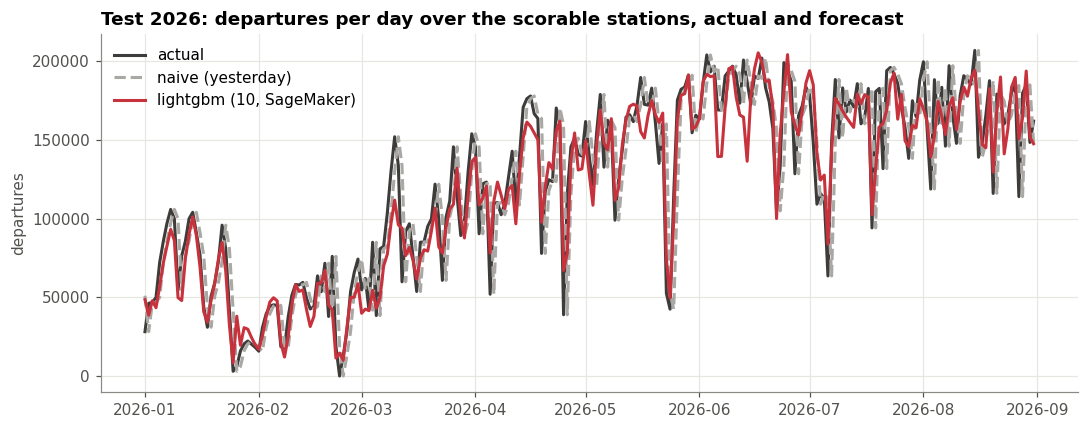

City total per day, 243 days, mean 123.412 departures (05 §8 on these days: the summed rules at 29.834 and 26.937)


,MAE,RMSE,WAPE_%,bias,n
method,,,,,
naive (yesterday),"22.603,8","31.057,4","18,3","-438,1",243
"lightgbm (10, SageMaker)","12.381,7","15.811,1","10,0","-3.856,4",243


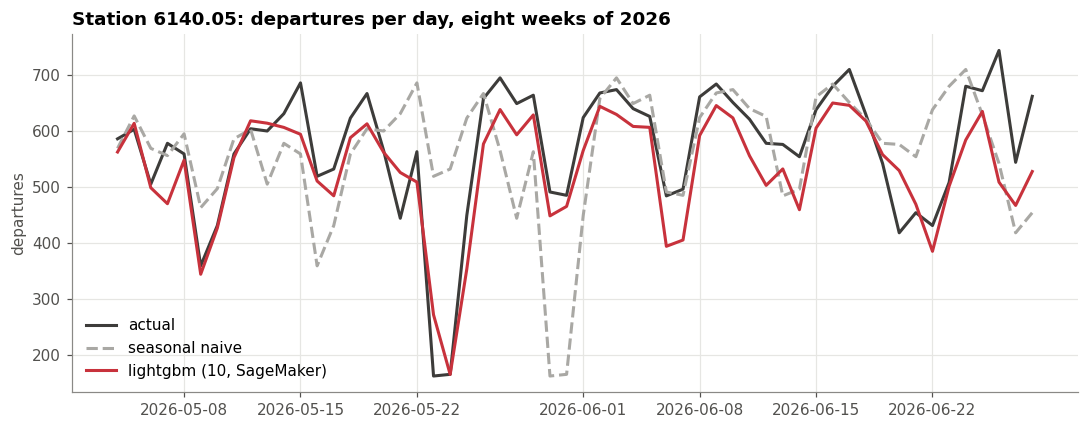

MAE over these 56 days: seasonal naive 94,7, lightgbm (10, SageMaker) 50,0


In [10]:
rules_day = [m for m in predictions["day"] if m not in CANDIDATES["day"] and m != "ridge (05)"]
best_rule_day = table_day.loc[rules_day].MAE.idxmin()
best_day = table_day.loc[[m for m in CANDIDATES["day"] if m in table_day.index]].MAE.idxmin()
day_rows = test["day"]
city = pd.DataFrame({"actual": day_rows.groupby("day").y_day.sum(),
                     best_rule_day: predictions["day"][best_rule_day].groupby(day_rows.day).sum(),
                     best_day: predictions["day"][best_day].groupby(day_rows.day).sum()})

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(city.index, city.actual, color="#3d3c3a", label="actual")
ax.plot(city.index, city[best_rule_day], color="#a9a8a4", linestyle="--", label=best_rule_day)
ax.plot(city.index, city[best_day], color="#c8323c", label=best_day)
ax.set_title("Test 2026: departures per day over the scorable stations, actual and forecast")
ax.set_ylabel("departures")
ax.legend()
plt.tight_layout()
plt.show()
print(f"City total per day, {fmt(len(city))} days, mean {fmt(city.actual.mean(), ',.0f')} departures "
      f"(05 §8 on these days: the summed rules at 29.834 and 26.937)")
display(score_table(city, {m: city[m] for m in (best_rule_day, best_day)}, "actual").round(1))

busiest = day_rows.groupby("station_key").y_day.sum().idxmax()
window = day_rows[(day_rows.station_key == busiest) & (day_rows.day >= "2026-05-04") & (day_rows.day < "2026-06-29")].sort_values("day")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(window.day, window.y_day, color="#3d3c3a", label="actual")
ax.plot(window.day, window.dep_lag_7, color="#a9a8a4", linestyle="--", label="seasonal naive")
ax.plot(window.day, predictions["day"][best_day].loc[window.index], color="#c8323c", label=best_day)
ax.set_title(f"Station {busiest}: departures per day, eight weeks of 2026")
ax.set_ylabel("departures")
ax.legend()
plt.tight_layout()
plt.show()
print(f"MAE over these {len(window)} days: seasonal naive {fmt((window.dep_lag_7 - window.y_day).abs().mean(), '.1f')}, "
      f"{best_day} {fmt((predictions['day'][best_day].loc[window.index] - window.y_day).abs().mean(), '.1f')}")

## 6. The choice, written to disk

The rule of part 1 applied to the test tables: per horizon the candidate with the lowest test MAE, the smaller model
file when two are within `TIE_PERCENT`. The choice goes to `models/citibike/09_choice.json` with everything the
deployment needs to find and describe the model: the run folder, the family, the hyperparameters, the inputs in the
order the pipeline expects them, the test and validation metrics, the file size and the date; the test MAE of every
other method is recorded next to it, the bar the choice clears. The API loads the run folder's `model.joblib`; the
retraining pipeline refits the same family with the same hyperparameters on every push (the deployment's job, as
part 1 says).

In [11]:
def choose(horizon: str, table: pd.DataFrame) -> dict:
    """The rule of part 1 on the test table of a horizon: lowest MAE; the smaller model within TIE_PERCENT of it."""
    present = registry.loc[horizon].query("present")
    scored = table.loc[[label for label in present.index if label in table.index]].sort_values("MAE")
    close = scored[scored.MAE <= scored.MAE.iloc[0] * (1 + TIE_PERCENT / 100)]
    label = present.loc[close.index, "model MB"].idxmin() if len(close) > 1 else scored.index[0]
    folder = CANDIDATES[horizon][label]
    result = json.loads((MODELS_DIR / folder / "metrics.json").read_text(encoding="utf-8"))
    return {"candidate": label, "run_folder": folder, "family": result["family"], "hyperparameters": result["hyperparameters"],
            "inputs": result["inputs"], "model_mb": float(present.loc[label, "model MB"]),
            "test": {k: (int(v) if k == "n" else round(float(v), 4)) for k, v in table.loc[label].items() if k not in ("validation MAE", "shift %")},
            "validation_mae": round(float(table.loc[label, "validation MAE"]), 4),
            "test_mae_of_others": {m: round(float(table.loc[m, "MAE"]), 4) for m in table.index if m != label},
            "rule": f"lowest test MAE; within {TIE_PERCENT} % the smaller model file", "chosen_on": date.today().isoformat()}


choice = {horizon: choose(horizon, table) for horizon, table in [("day", table_day), ("rest_of_month", table_rest)]}
CHOICE_FILE.write_text(json.dumps(choice, indent=1), encoding="utf-8")
for horizon, c in choice.items():
    others = ", ".join(f"{m} {v:.2f}" for m, v in c["test_mae_of_others"].items())
    print(f"{horizon}: {c['candidate']} ({c['run_folder']}, {c['model_mb']} MB), test MAE {c['test']['MAE']:.2f}, "
          f"WAPE {c['test']['WAPE_%']:.1f} % (validation MAE {c['validation_mae']:.2f}); the others: {others}")
print(f"written to {CHOICE_FILE.name} in {CHOICE_FILE.parent}")

day: lightgbm (08, tuned) (08_day_lightgbm, 12.2 MB), test MAE 9.80, WAPE 17.6 % (validation MAE 9.63); the others: lightgbm (10, SageMaker) 9.75, lightgbm (07) 10.08, ridge (05) 12.60, naive (yesterday) 15.43, mean of the same weekday, 4 weeks 15.57, seasonal naive (same weekday last week) 17.77
rest_of_month: extra trees (08, tuned) (08_rest_of_month_extra_trees, 1005.6 MB), test MAE 121.54, WAPE 13.7 % (validation MAE 108.47); the others: extra trees (10, SageMaker) 120.98, extra trees (07) 123.20, ridge (05) 150.44, pace, last 7 days x days left 154.55, pace, month to date x days left 161.58, last year, same period x growth 167.56
written to 09_choice.json in C:\localdata\repo\cloud-ai-avenue-5\models\citibike


## 7. Reading and conclusions

Run of 8 October 2026 (team lead) on the test period January - August 2026, and again on 10 October with the two
candidates of 10 on disk; the outputs above are the second run. Every assertion passed in both: 537.818 and 536.450
scorable test rows (05 §5; 2.328 and 2.325 stations) matched their test inputs, and each of the six pipelines
reproduced its saved validation predictions. Test MAE in departures per station-day, WAPE in brackets:

| Horizon | Best rule (test MAE) | Ridge (05) | 07 | 08 | 10 | Final model | Gain over the rule |
| --- | --- | --- | --- | --- | --- | --- | --- |
| day | yesterday **15,43** (27,7 %) | 12,60 (22,6 %) | 10,08 (18,1 %), bias +1,0 | **9,80** (17,6 %), bias -1,7 | 9,75 (17,5 %), bias -1,7 | LightGBM of 08: `08_day_lightgbm`, 12 MB | 36 % (22 % over the ridge, 2,7 % over 07) |
| rest of month | weekly pace **154,6** (17,4 %) | 150,4 (17,0 %) | 123,2 (13,9 %), bias -13,3 | **121,5** (13,7 %), bias -10,9 | 121,0 (13,6 %), bias -8,8 | extra trees of 08: `08_rest_of_month_extra_trees`, 1,0 GB | 21 % (19 % over the ridge, 1,3 % over 07) |

- **10's models are the best on the test by half a percent, and the rule keeps 08.** Day 9,75 against 9,80, rest
  of month 121,0 against 121,5: both inside the 1 % band of the rule, where the smaller model wins, and 10's models
  are four and two times the size (46 MB and 2,0 GB against 12 MB and 1,0 GB). The rule was fixed before any test
  number was seen; this is the case it was written for. 10's widened search was right about the direction (deeper
  trees, the absolute error, a smaller leaf): the 1 % it gained on validation survives on the test at half that,
  bought with size. 07's extra trees (0,5 GB) at 123,2 are 1,8 % above the best, outside the band.
- **The ranking of 2025 holds on 2026, and the models lose less than the rules.** Day: from validation to test the
  MAE shifts +2,2 % (10), +1,8 % (08), +0,6 % (07), +5,7 % (ridge) and +3,8 to +10,5 % (the rules); the best rule
  is now yesterday, not the 4-week mean. The tuned models keep most of what they had over 07 on validation: a search
  on one year is a little optimistic, as expected, but the gain is real on a year it never saw. Rest of month: the
  three extra trees shift +12 to +12,6 %, the ridge +0,2 % and the weekly pace +3,7 %. The trees lean on inputs that
  moved between the years (the year-earlier rates, the month pattern), so their lead over the ridge shrinks from
  28 % to 19 %; it is still the largest gain of the project.
- **Where the tuned models gain, and where they do not.** The gain of 08 and 10 over 07 sits with the quiet
  stations (Q1 2,19 and 2,14 against 2,65, Q2 4,19 against 4,50; Q3 and Q4 within 0,5): the absolute error aims at
  the median, which is what a count near zero needs. Holidays are no weak spot any more (08: 9,76 on a holiday,
  9,34 the week after, 9,82 on other days; the seasonal naive rule 17,3 / 22,8 / 17,6). A wet day is 7 % worse than
  a dry one for 08 and 5 % for 10 (10,31 and 10,11 against 9,64 and 9,63; 07 9 %, ridge 14 %, seasonal naive 16 %),
  with a bias of +0,6 and +0,5 (seasonal naive +10,3): the models know the day's weather and use it. The RMSE is
  the one metric where 07 holds (19,24, like 10; 08 19,40): the absolute error gives up the squared errors of the
  storm days for the median, and the bias turns negative.
- **Rest of month: the margins are thin all the way down.** 08 over 07 1,4 %, 10 over 08 0,5 %; the three are within
  0,3 points of WAPE in every cut, and the differences sit in the long horizons (22 - 31 days: 198,4 / 194,9 / 193,8
  for 07 / 08 / 10). The 2 GB and 1 GB models buy little over the 0,5 GB one here; a deployment that must hold the
  model in its own memory may take 07's at 1,4 % more error, a deployment that serves it from AWS (11) takes 09's
  choice as it is.
- **The months.** Day: the MAE is lowest in winter (5 - 6 in January and February) and 10 - 12 in summer, with the
  volume; the WAPE the other way round (24 - 27 % in winter, 15 - 17 % in summer): quiet, weather-driven days are
  hard in percent. The rules' WAPE in winter is 49 - 58 %, so that is where the models gain most. Rest of month:
  January (WAPE 43 - 44 %: a month forecast from a frozen week, with two days near zero in the late-January storm)
  and March (23 %: the spring ramp, which the first days of the month cannot know) are the weak months, from April
  on 9 - 11 %. The ridge is worse than the pace from April on, as 05 found; the trees are the best method in every
  month.
- **2026 ran busier than its first days implied.** The rest-of-month bias is -11 (08) and -9 (10) on test against -6
  on validation and, beyond 21 days, -65 and -60 against +19 in 2025. A model fitted on 2021 - 2024 with 2025 unseen
  cannot know the growth of 2026; the retraining on 2021 - 2025 before deployment is the answer, not more tuning.
- **The city, and one station.** The station forecasts of the best day model (10's in this run) summed per day: MAE
  12.382 departures on a mean of 123.412 (WAPE 10,0 %, bias -3.856: 3 % too few; 08's gave 12.292 in the first run),
  against 22.604 for yesterday's total and 29.799 for the city-level seasonal naive of 03 §6.3. The chart follows the
  storm days (the model has the day's weather) and lags the spring ramp of March and April. The busiest station of
  2026 (6140.05) over eight weeks: seasonal naive 94,7, 10's LightGBM 50,0 where 08's gave 59,3: on one busy station
  the deeper trees do matter, which the station-day MAE over 537.818 rows averages away.
- **Runtime:** the six pipelines predicted their test rows in 6 - 19 s each, the 2 GB model included; the notebook
  ran in a few minutes.

**What the deployment takes from here:** `09_choice.json` names the two 08 models with their run folders, families,
hyperparameters and inputs in order; 11 trains exactly those configurations once more on SageMaker (the same script
and seed give the same model, 10 §4) and serves them from there, so the server holds no model at all. The error to
quote next to a forecast: day MAE 9,8 (WAPE 18 %; per size quartile 2,2 / 4,2 / 9,3 / 23,6), rest of month 121,5
(WAPE 14 %; per days left 45 / 97 / 126 / 195). Retrain the same configurations on 2021 - 2025 before the first
deployment and on every push. Nothing is tuned after this notebook; 10's search is recorded as the better
configuration the rule declined for its size.

## Appendix: the dry run of 8 October, the expected runtime, the failures to expect

**Dry run** (Claude, 8 October, this kernel's environment, before the run on the test period). Every cell was executed by `nbclient` in the kernel's environment (Python 3.13.7, scikit-learn 1.9.1, lightgbm 4.7.0) on **75 of the 2.455 stations** (110.584 rows of the real Parquet cache; `load_features()` stubbed to that sample, the model inputs and the run folders in a temporary folder, the ridge files of 05 copied there): 11 s, no error, every assertion passed, both charts drawn. The run folders were made for the occasion with `train.py` on the sample's inputs (07- and 08-like settings, 100 LightGBM trees and 20 extra trees), so the 10 candidates were reported missing and skipped, as they will be until 10 has run; the four pipelines reproduced their saved validation predictions on 2.000 rows exactly; 14.938 and 14.908 scorable test rows matched their test inputs; the test tables, the cuts and the per-month tables came out for every method; `09_choice.json` was written in the temporary folder (the day choice fell to the 07-like model on the sample; the tie rule was not triggered). **The numbers of that run mean nothing for the reading**: models of 100 and 20 trees on 75 stations.

**Expected runtime on the test period**: an extrapolation, not a measurement. The feature table loads in seconds
from its cache; the rules and the ridge take seconds; a LightGBM pipeline predicts 540.000 rows in seconds; the two
extra trees pipelines (499 MB and 1 GB) take the time: ten to twenty seconds to load and a minute or two to predict
536.000 rows with 200 deep trees each. Expect **5 - 10 minutes** for the whole notebook and a few GB of memory
while an extra trees model is loaded next to the feature table (1,2 GB in pandas). **Measured in the run of 8 October:** the four pipelines predicted their test rows in 7 s (07 LightGBM), 9 s (08 LightGBM), 5 s (07 extra trees, 499 MB) and 7 s (08 extra trees, 1,0 GB), loading included: the estimate of a minute or two per extra trees model was far too pessimistic. The whole notebook ran in a few minutes; the cells carry no total timer.

| Symptom | Cause | Fix |
| --- | --- | --- |
| an assertion in part 0 | 07 §2 has not been run on this machine: no test inputs | run 07 part 2 |
| "is not on disk" printed for a 10 candidate | 10 has not run, or unpacked its artefacts under another name | expected until 10 has run; then unpack `model.tar.gz` and `output.tar.gz` into `10_<horizon>_<family>/` |
| the assertion "the test inputs are not the scorable test rows" | the Parquet cache and the model inputs were built from different versions of the feature table | run 07 §2 again on the current cache |
| the assertion "differs from its saved validation predictions" | the run folder's `model.joblib` was overwritten after its predictions file (a rerun, or 08's refit pointed at a 07 folder) | rerun the notebook that owns the folder, top to bottom |
| `MemoryError` while an extra trees model loads | the 1 GB pipeline next to the feature table and the predictions of the other candidates | restart the kernel and run parts 0 - 2 alone first; or score the 07 extra trees, note the numbers, and drop it from `CANDIDATES` |
| a candidate below a rule in a test table | the model does not generalise to 2026 on that horizon | a finding for part 7, not an error: the rule of choice ranks candidates only |
| `no 05_ridge_day.joblib` printed, no ridge row | 05 §7.1 has not been run on this laptop | run 05 part 7, or read the tables without the floor |